In [40]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split, Subset

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

from kaggle.api.kaggle_api_extended import KaggleApi

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [41]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")
# 데스크탑: cuda

현재 선택된 장치: xpu


In [42]:
load_dotenv()

print(os.environ["KAGGLE_API_TOKEN"][:4])

KGAT


In [43]:
api = KaggleApi()
api.authenticate()

# output_dir = r"E:\kdf\machine_learning\resource"
output_dir = r"C:\kdt_0900_pjh\machine_learning\resource\datasets"
os.makedirs(output_dir, exist_ok=True)
# api.dataset_download_files(r"asdasdasasdas/garbage-classification", path=output_dir, unzip=True)

print("다운로드 완료")

다운로드 완료


## Garbage Classification(쓰레기 재질 분류 데이터셋)
| 파일명 | 설명 | 이미지수|
| :--- | :--- | :--- |
| cardboard | 판지 | 403장 |
| glass | 유리 | 501장 |
| metal | 금속 | 410장 |
| paper | 종이 | 594장 |
| plastic | 플라스틱 | 482장 |
| trash | 일반 쓰레기 | 137장 |
| **합계** | | **2,527장** | |

In [44]:
folder_name = r"Garbage_classification"
file_path = os.path.join(output_dir, folder_name)

base_dataset = ImageFolder(root=file_path, transform=None)

# 클래스명 매핑
class_dict = dict(enumerate(base_dataset.classes))

print(f"총 데이터수: {len(base_dataset)}")
print(f"클래스 수: {len(class_dict)}")
print(f"라벨 매핑: {class_dict}")

총 데이터수: 2527
클래스 수: 6
라벨 매핑: {0: 'cardboard', 1: 'glass', 2: 'metal', 3: 'paper', 4: 'plastic', 5: 'trash'}


In [45]:
# ImageNet 사전학습 가중치를 사용하기 때문에 기준값을 써줘야한다.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# 훈련데이터: 증강함
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# 검증데이터: 증강안함
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [46]:
train_idx, test_idx = train_test_split(
    range(len(base_dataset)),
    test_size=0.2, 
    stratify=base_dataset.targets, 
    random_state=42
)

train_subset = Subset(base_dataset, train_idx) 
test_subset = Subset(base_dataset, test_idx)

len(train_subset), len(test_subset)

(2021, 506)

In [47]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [48]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)  
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [49]:
imgs, labels = next(iter(train_dataloader))

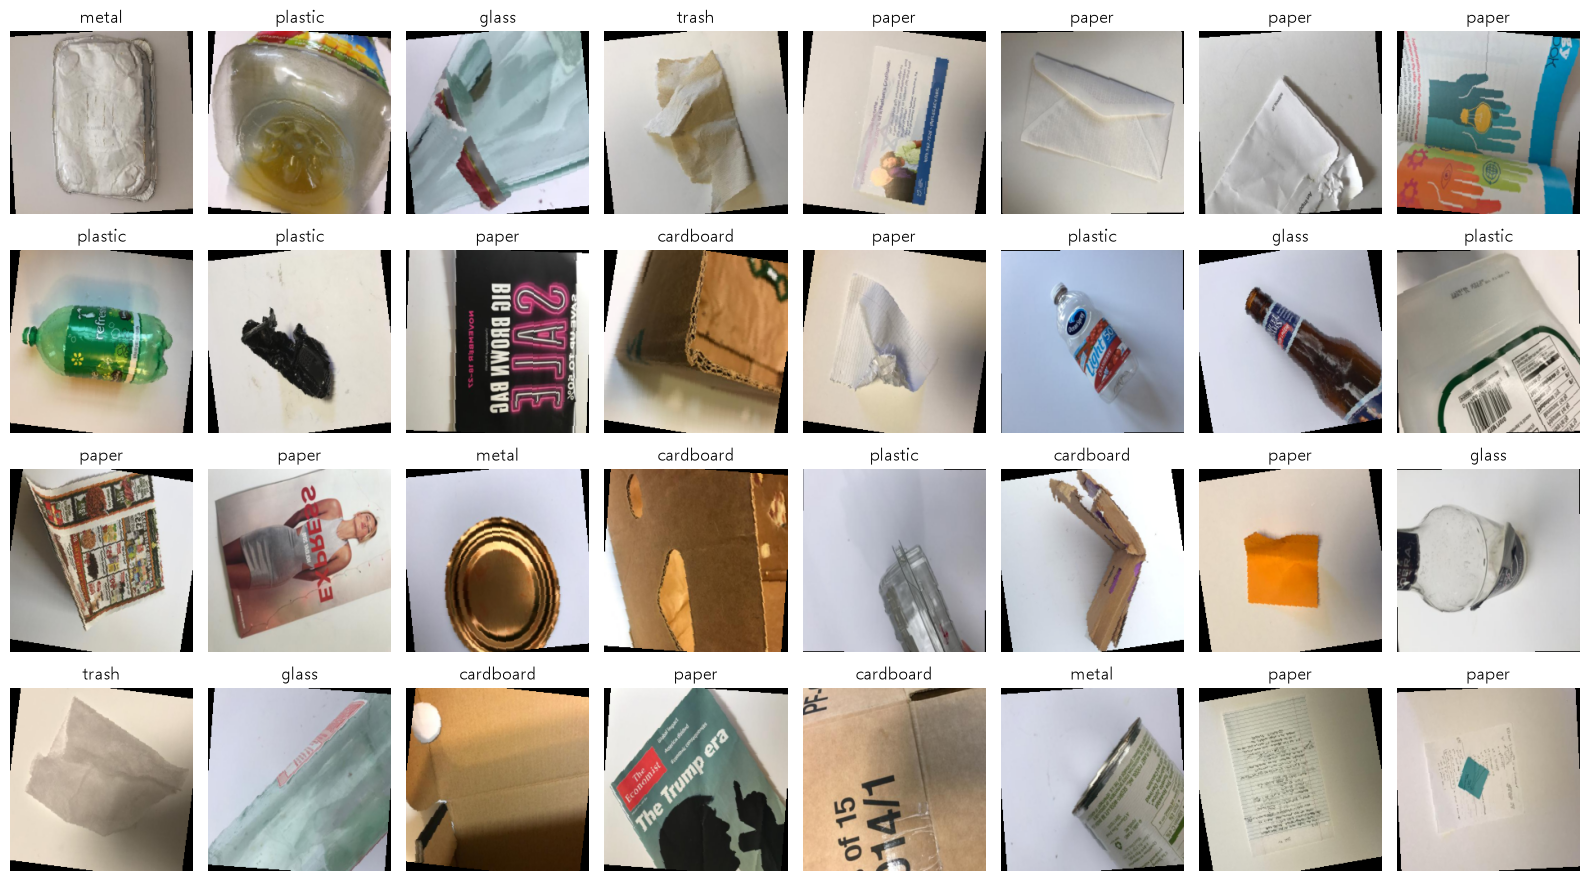

In [50]:
fig, axes = plt.subplots(4, 8, figsize=(16, 9))

# RGB 텐서가 (3, 224, 224)인데 imshow는 (224, 224, 3)으로 채널이 뒤에 있어야하기 때문에 
# permute를 활용하여 순서를 바꿔준다.
mean_view = torch.tensor(mean).view(3, 1, 1)
std_view = torch.tensor(std).view(3, 1, 1)

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# base_path = r"E:\kdf\machine_learning\resource"
base_path = r"C:\kdt_0900_pjh\machine_learning\resource"
model_weights_path = os.path.join(base_path, "weights")
os.makedirs(model_weights_path, exist_ok=True)

# PyTorch Hub 기본 캐시 경로를 변경
torch.hub.set_dir(model_weights_path)

base_model = models.resnet18(weights="IMAGENET1K_V1").to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\kdt_0900_pjh\machine_learning\resource\weights\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 27.1MB/s]


In [51]:
for param in base_model.parameters():
    param.requires_grad = False

In [16]:
base_model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [65]:
# inplace=False 원본 데이터를 수정하지 않고 dropout이 적용된 새로운 결과의 데이터로 반
base_model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.3, inplace=False),
    nn.Linear(128, 6),
).to(device)

In [66]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device):
    model.train()
    sum_loss = 0.0
    sum_acc = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        batch_loss = 0.0
        
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_loss += batch_loss

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_acc += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] | [Batch Loss: {batch_loss:.4f}] | [Batch Accuracy: {acc:.2f}]")

    avg_loss = sum_loss / len(dataloader)
    avg_acc = sum_acc / len(dataloader)

    return avg_loss, avg_acc

In [67]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device):
    model.eval()
    sum_loss = 0.0
    sum_acc = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_loss += loss.item()

        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_acc += acc

    avg_loss = sum_loss / len(dataloader)
    avg_acc = sum_acc / len(dataloader)

    return avg_loss, avg_acc

In [68]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [], 
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }
    best_val_acc = 0.0

    # 학습
    print(f"===================== {model_name} 학습 시작 =====================")
    for epoch in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}")
        print(f"[Epoch: {epoch + 1}/{epochs}] | Vaildation Loss: {val_loss:.4f} | Vaildation Accuracy: {val_acc:.2f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"===================== {model_name} 학습 종료 =====================")
    return history

In [69]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(base_model.fc.parameters(), lr=0.001)

In [22]:
history = train_model_multiclass(
    model=base_model,
    model_name="Resnet-Multiclass",
    train_loader=train_dataloader,
    val_loader=val_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=100,
    device=device,
    save_base_dir=os.path.join(base_path, r"weights")
)

===================== Resnet-Multiclass 학습 시작 =====================
[Batch 20/64] | [Batch Loss: 1.3403] | [Batch Accuracy: 46.88]
[Batch 40/64] | [Batch Loss: 1.0927] | [Batch Accuracy: 56.25]
[Batch 60/64] | [Batch Loss: 1.1782] | [Batch Accuracy: 59.38]
[Epoch: 1/5] | Train Loss: 1.2931 | Train Accuracy: 50.28
[Epoch: 1/5] | Vaildation Loss: 0.8794 | Vaildation Accuracy: 73.36
[Batch 20/64] | [Batch Loss: 1.0967] | [Batch Accuracy: 59.38]
[Batch 40/64] | [Batch Loss: 0.7619] | [Batch Accuracy: 71.88]
[Batch 60/64] | [Batch Loss: 0.8822] | [Batch Accuracy: 62.50]
[Epoch: 2/5] | Train Loss: 0.8697 | Train Accuracy: 69.10
[Epoch: 2/5] | Vaildation Loss: 0.7268 | Vaildation Accuracy: 76.05
[Batch 20/64] | [Batch Loss: 0.4715] | [Batch Accuracy: 87.50]
[Batch 40/64] | [Batch Loss: 0.5995] | [Batch Accuracy: 75.00]
[Batch 60/64] | [Batch Loss: 1.0409] | [Batch Accuracy: 62.50]
[Epoch: 3/5] | Train Loss: 0.7367 | Train Accuracy: 73.42
[Epoch: 3/5] | Vaildation Loss: 0.7093 | Vaildation Acc

In [70]:
base_path

'C:\\kdt_0900_pjh\\machine_learning\\resource'

In [71]:
model_name = "Resnet-Multiclass"
best_model_path = os.path.join(base_path, "weights", model_name, "best_model.pth")

# 가중치 없이 best_model만 가져오기
res_model = models.resnet18(weights=None)

res_model.fc = nn.Sequential(
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 6)
)

res_model.load_state_dict(torch.load(best_model_path, map_location=device))
res_model = res_model.to(device)

## 혼동행렬 및 Accuracy 측정

Test Loss: 0.6152  Test Accuracy: 78.58%

              precision    recall  f1-score   support

   cardboard       0.96      0.81      0.88        81
       glass       0.74      0.80      0.77       100
       metal       0.67      0.83      0.74        82
       paper       0.77      0.95      0.85       119
     plastic       0.89      0.61      0.72        97
       trash       0.73      0.41      0.52        27

    accuracy                           0.78       506
   macro avg       0.79      0.73      0.75       506
weighted avg       0.80      0.78      0.78       506



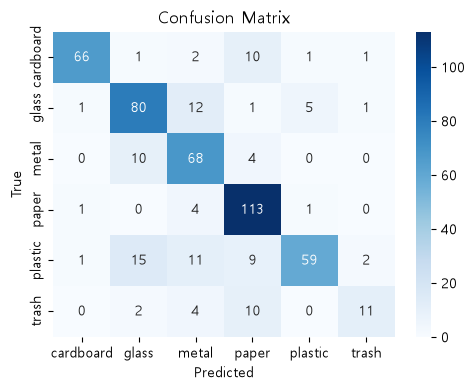

In [72]:
res_model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for batch_imgs, batch_labels in val_dataloader:
        outputs = res_model(batch_imgs.to(device))
        probs = F.softmax(outputs, dim=1)
        _, batch_preds = outputs.max(1)
        y_pred.extend(batch_preds.cpu().tolist())
        y_true.extend(batch_labels.tolist())
        y_prob.append(probs.cpu())

val_loss, val_acc = evaluate_multiclass(res_model, val_dataloader, criterion, device)
print(f"Test Loss: {val_loss:.4f}  Test Accuracy: {val_acc:.2f}%\n")

target_names = [class_dict[i] for i in range(len(class_dict))]
print(classification_report(y_true, y_pred, target_names=target_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

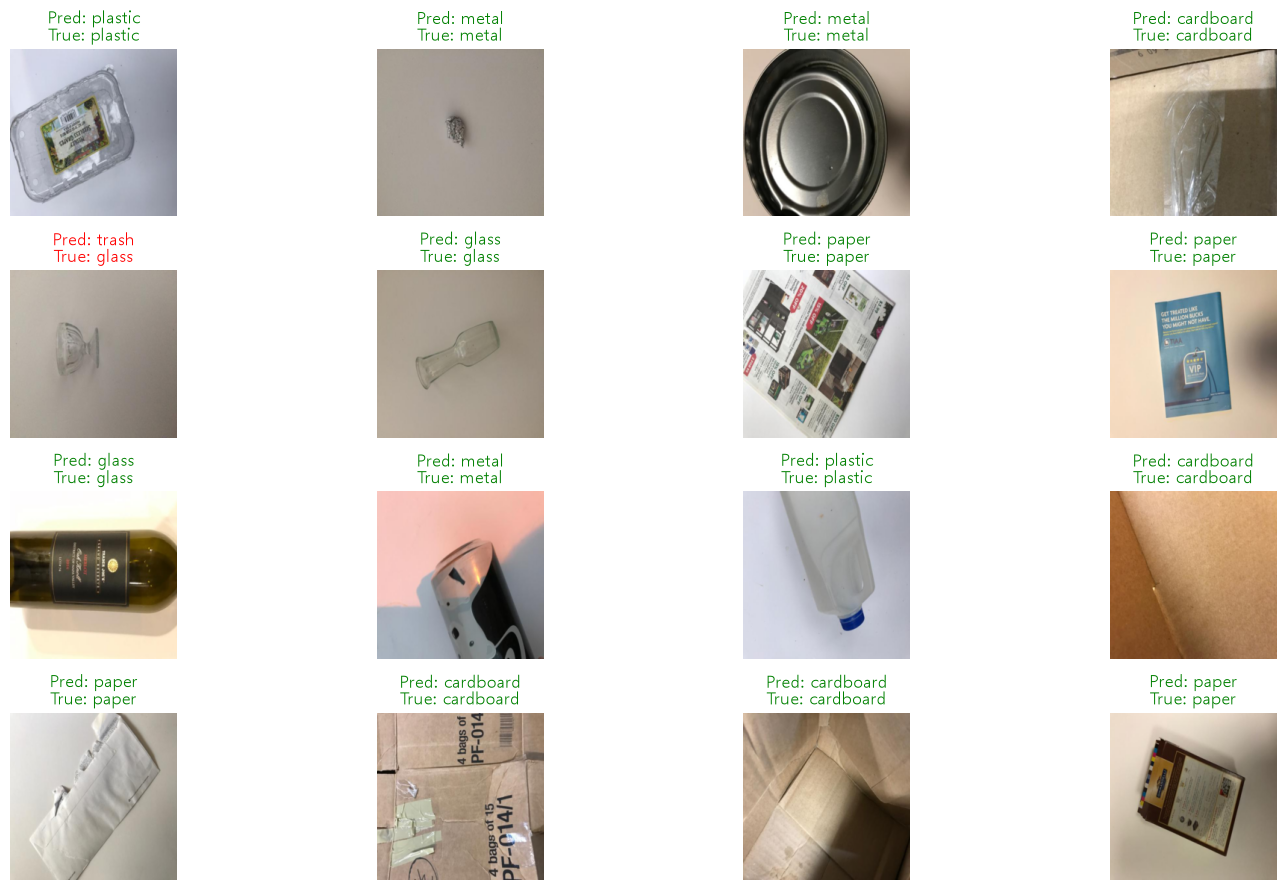

In [73]:
res_model.eval()

imgs, labels = next(iter(val_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = res_model(imgs_dev)
    _, preds = outputs.max(1) 

# 시각화는 CPU에서 실행되기 떄문에 텐서를 CPU로 되돌린다.
img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

fig, axes = plt.subplots(4, 4, figsize=(16, 9))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    # 역정규화를 해주지 않으면 이미지가 뭉개질 수 있다.
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1), cmap="gray", vmin=0, vmax=1)
    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.tight_layout()   
plt.show()

## 오분류 중 예측 확률이 가장 높았던 10가지

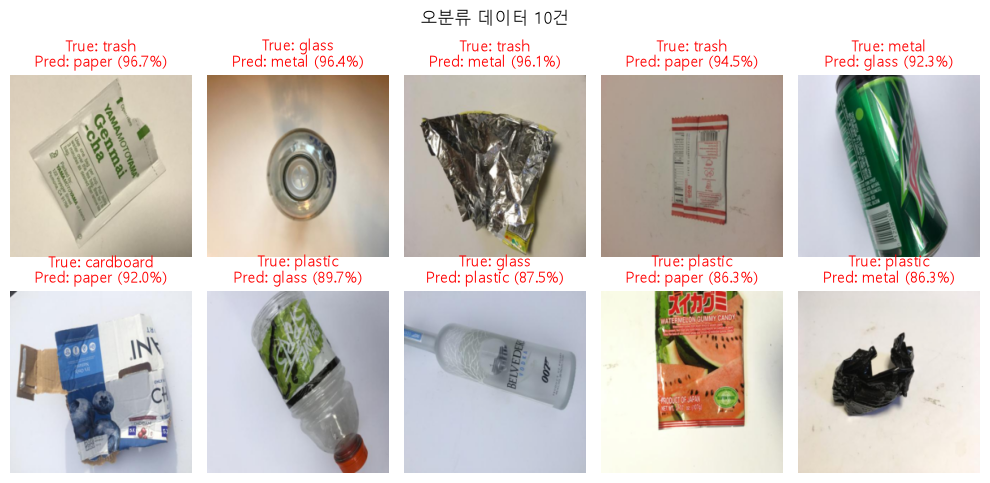

In [75]:
res_model.eval()

incorrect_samples = []

with torch.no_grad():
    for batch_imgs, batch_labels in val_dataloader:
        outputs = res_model(batch_imgs.to(device))
        probs = F.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1)

        # 배치를 한 장씩 돌면서 오분류만 담는다. 
        for img, true_label, pred_label, prob in zip(batch_imgs, batch_labels, preds.cpu(), probs.cpu()):
            if true_label != pred_label:
                incorrect_samples.append({
                    "img": img,
                    "true_label": int(true_label),
                    "pred_label": int(pred_label),
                    "prob": float(prob[pred_label]),        
                    "true_prob": float(prob[true_label]),   
                })

# 예측확률이 높은 순으로 정렬
incorrect_samples.sort(key=lambda s: s["prob"], reverse=True)

# 오분류가 10개 미만일 경우를 방지
num = min(10, len(incorrect_samples))
cols = 5
rows = (num + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(10, 5))
axes = np.atleast_1d(axes).flatten()

# rows가 1이면 axes가 1차원이 되기 때문에 형태를 통일함
for ax, sample in zip(axes, incorrect_samples[:num]):
    img = sample["img"].cpu()
    ax.imshow((img * std_view + mean_view).permute(1, 2, 0).clamp(0, 1))

    true_name = class_dict[int(sample["true_label"])]
    pred_name = class_dict[int(sample["pred_label"])]

    title = f"True: {true_name}\nPred: {pred_name}"
    if "prob" in sample:                       
        title += f" ({float(sample['prob']) * 100:.1f}%)"

    ax.set_title(title, color="red", fontsize=11)
    ax.axis("off")

for ax in axes[num:]:                            
    ax.axis("off")

plt.suptitle(f"오분류 데이터 {num}건")
plt.tight_layout()
plt.show()

In [77]:
# 예측 확률을 내림차순으로 정렬
# 예측 확률이 높은데 정답률이 맞으면 이미지의 편향을 의심해볼 수 있음
rows = []
for num, sample in enumerate(incorrect_samples[:10], 1):
    rows.append({
        "No": num,
        "정답 라벨": class_dict[sample["true_label"]],
        "예측 라벨": class_dict[sample["pred_label"]],
        "예측 확률": f"{sample['prob'] * 100:.1f}%",
        "정답 확률": f"{sample['true_prob'] * 100:.1f}%",
    })

wrong_df = pd.DataFrame(rows)
wrong_df

,No,정답 라벨,예측 라벨,예측 확률,정답 확률
0,1,trash,paper,96.7%,0.2%
1,2,glass,metal,96.4%,3.0%
2,3,trash,metal,96.1%,1.5%
3,4,trash,paper,94.5%,1.9%
4,5,metal,glass,92.3%,4.7%
5,6,cardboard,paper,92.0%,7.0%
6,7,plastic,glass,89.7%,9.9%
7,8,glass,plastic,87.5%,11.5%
8,9,plastic,paper,86.3%,0.5%
9,10,plastic,metal,86.3%,1.7%


정분류 397건 / 오분류 109건 → 대상 5장

[1] 정분류 | cardboard45.jpg
    True: cardboard (100.0%) → Pred: cardboard (100.0%)
    최고 집중: 격자 (5,1) | 중앙 집중도 16.4% | 테두리 비중 40.1%

[2] 정분류 | cardboard97.jpg
    True: cardboard (99.9%) → Pred: cardboard (99.9%)
    최고 집중: 격자 (5,1) | 중앙 집중도 18.2% | 테두리 비중 40.5%

[3] 정분류 | cardboard365.jpg
    True: cardboard (99.8%) → Pred: cardboard (99.8%)
    최고 집중: 격자 (1,1) | 중앙 집중도 17.5% | 테두리 비중 40.0%

[4] 오분류 | trash5.jpg
    True: trash (0.2%) → Pred: paper (96.7%)
    최고 집중: 격자 (4,4) | 중앙 집중도 42.9% | 테두리 비중 9.2%

[5] 오분류 | glass453.jpg
    True: glass (3.0%) → Pred: metal (96.4%)
    최고 집중: 격자 (3,3) | 중앙 집중도 49.3% | 테두리 비중 5.7%



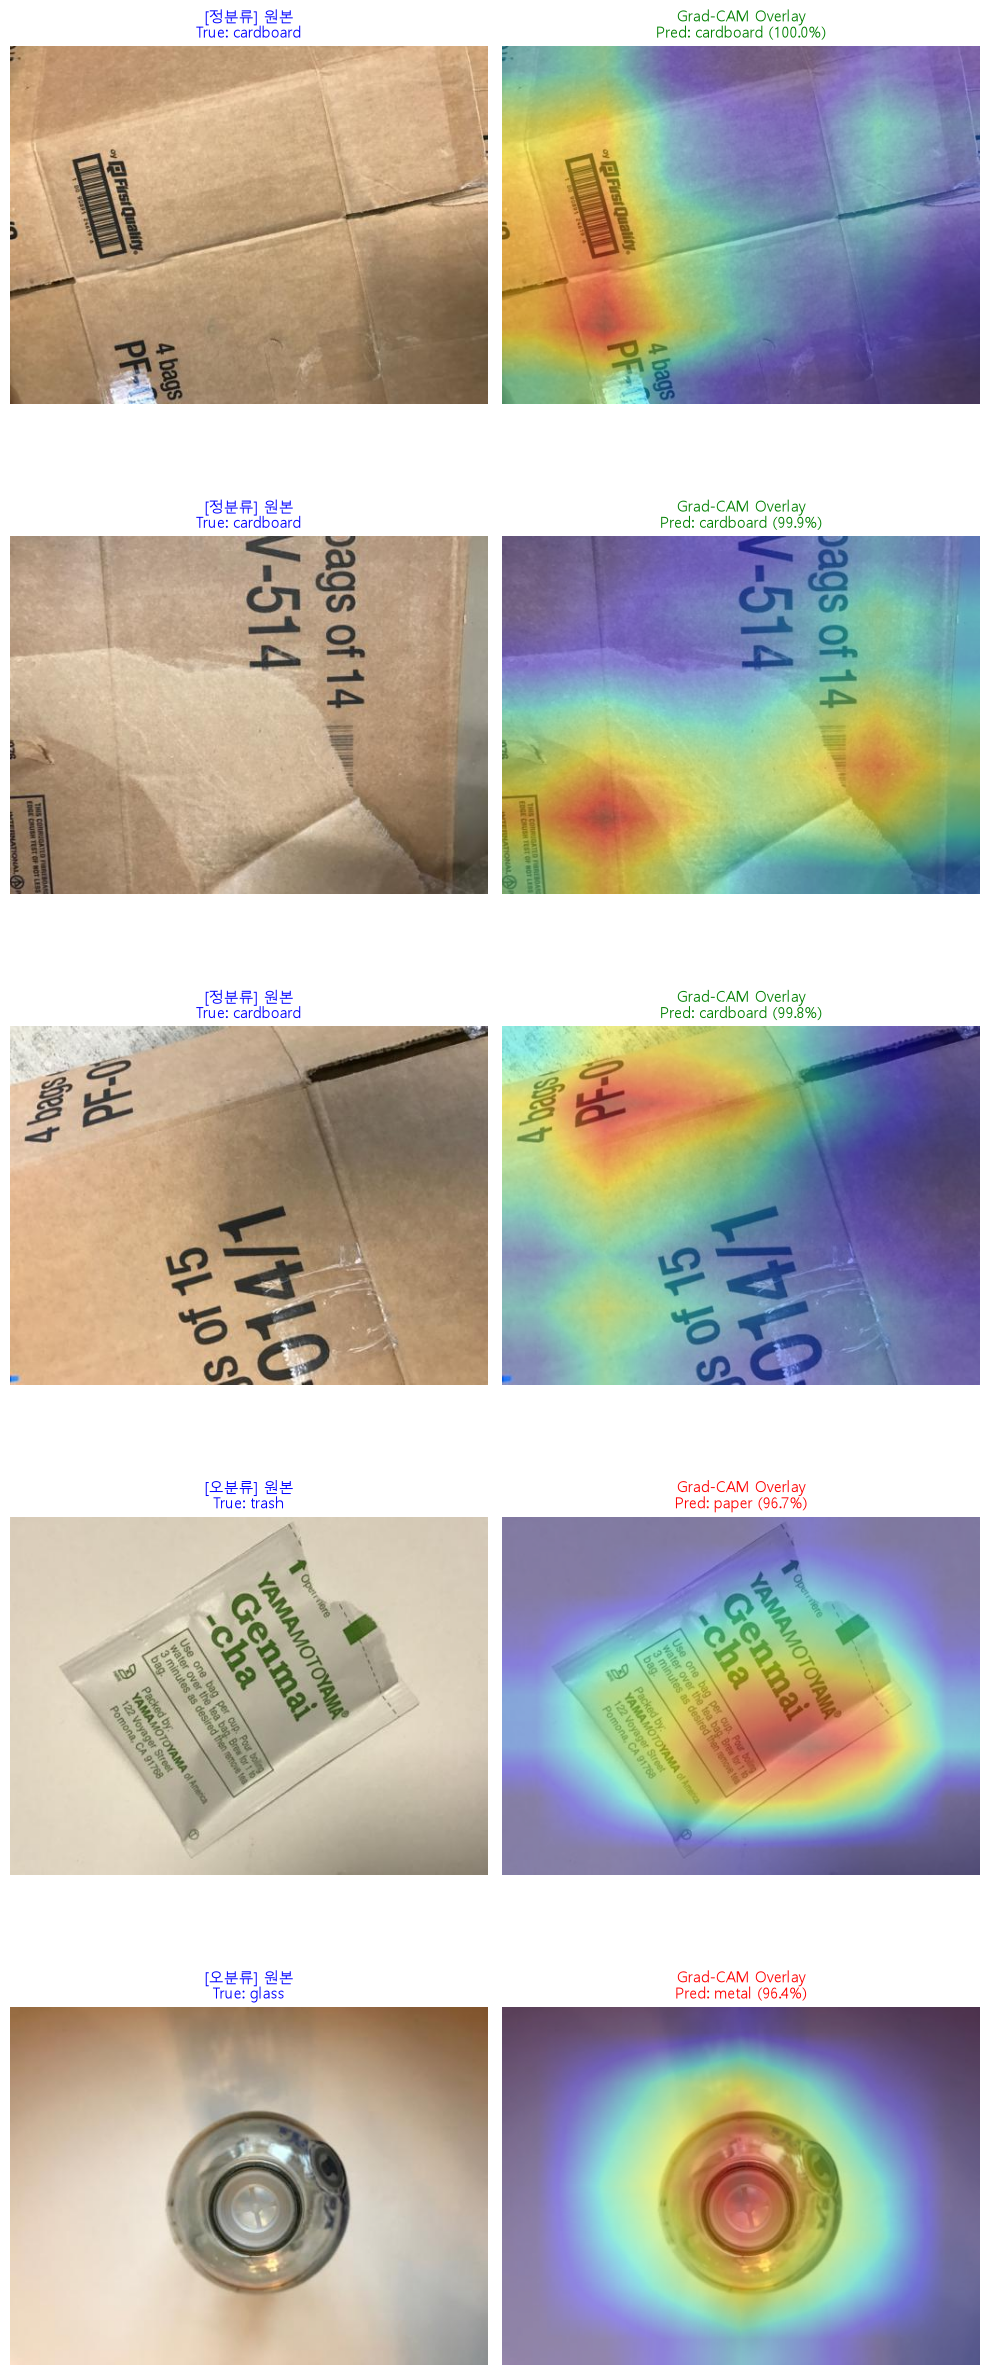

In [76]:
res_model.eval()

store = {"act": None, "grad": None}
store_fwd = lambda m, i, o: store.__setitem__("act", o.detach())
store_bwd = lambda m, gi, go: store.__setitem__("grad", go[0].detach())

for p in res_model.parameters():
    p.requires_grad_(True)          

target_layer = [m for m in res_model.modules() if isinstance(m, nn.Conv2d)][-1]
h_fwd = target_layer.register_forward_hook(store_fwd)
h_bwd = target_layer.register_full_backward_hook(store_bwd)

records, offset = [], 0
with torch.no_grad():
    for bi, bl in val_dataloader:
        pb = F.softmax(res_model(bi.to(device)), dim=1).cpu()
        pr_ = pb.argmax(dim=1)
        for j in range(len(bl)):
            records.append({"pos": offset + j,
                            "ok": int(pr_[j]) == int(bl[j]),
                            "prob": float(pb[j][pr_[j]])})
        offset += len(bl)

ok_recs = sorted([r for r in records if r["ok"]], key=lambda r: r["prob"], reverse=True)
ng_recs = sorted([r for r in records if not r["ok"]], key=lambda r: r["prob"], reverse=True)
targets = ok_recs[:3] + ng_recs[:2]
print(f"정분류 {len(ok_recs)}건 / 오분류 {len(ng_recs)}건 → 대상 {len(targets)}장\n")

fig, axes = plt.subplots(len(targets), 2, figsize=(10, 5 * len(targets)), squeeze=False)

for row, rec in enumerate(targets):
    img_path = base_dataset.samples[val_idx[rec["pos"]]][0]
    true_idx = base_dataset.samples[val_idx[rec["pos"]]][1]

    original_image = Image.open(img_path).convert("RGB")
    input_tensor = val_transform(original_image).unsqueeze(0).to(device)

    res_model.zero_grad()
    output = res_model(input_tensor)                 
    probs = F.softmax(output, dim=1)[0]
    pred_idx = int(probs.argmax())
    output[0, pred_idx].backward()

    assert store["grad"] is not None, "훅이 호출되지 않았습니다. target_layer를 확인하세요."

    pooled = torch.mean(store["grad"], dim=[0, 2, 3])           
    weighted = store["act"][0] * pooled[:, None, None]          
    heatmap = torch.mean(weighted, dim=0).cpu().numpy()          
    heatmap = np.maximum(heatmap, 0)                             
    if heatmap.max() != 0:
        heatmap /= heatmap.max()

    heatmap_pil = Image.fromarray(np.uint8(255 * heatmap)).resize(
        original_image.size, Image.Resampling.BILINEAR)

    H, W = heatmap.shape
    total = heatmap.sum()
    pr, pc = np.unravel_index(heatmap.argmax(), heatmap.shape)
    center = heatmap[H//2-1:H//2+2, W//2-1:W//2+2].sum() / total * 100
    mask = np.ones_like(heatmap, dtype=bool); mask[1:H-1, 1:W-1] = False
    border = heatmap[mask].sum() / total * 100

    ok = (pred_idx == true_idx)
    mark, color = ("정분류", "green") if ok else ("오분류", "red")

    axes[row, 0].imshow(original_image)
    axes[row, 0].set_title(f"[{mark}] 원본\nTrue: {class_dict[true_idx]}", fontsize=11, color="blue")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(original_image)
    axes[row, 1].imshow(heatmap_pil, cmap="jet", alpha=0.4)      
    axes[row, 1].set_title(f"Grad-CAM Overlay\nPred: {class_dict[pred_idx]} "
                           f"({float(probs[pred_idx])*100:.1f}%)", fontsize=11, color=color)
    axes[row, 1].axis("off")

    print(f"[{row+1}] {mark} | {os.path.basename(img_path)}")
    print(f"    True: {class_dict[true_idx]} ({float(probs[true_idx])*100:.1f}%) → "
          f"Pred: {class_dict[pred_idx]} ({float(probs[pred_idx])*100:.1f}%)")
    print(f"    최고 집중: 격자 ({pr},{pc}) | 중앙 집중도 {center:.1f}% | 테두리 비중 {border:.1f}%\n")

plt.tight_layout()
plt.show()

h_fwd.remove(); h_bwd.remove()